In [3]:
%pip install torch torchvision

  Using cached sympy-1.14.0-py3-none-any.whl.metadata (12 kB)
  Using cached networkx-3.6.1-py3-none-any.whl.metadata (6.8 kB)
  Using cached mpmath-1.3.0-py3-none-any.whl.metadata (8.6 kB)
   ---------------------------------------- 0.0/124.1 MB ? eta -:--:--
   ---------------------------------------- 0.8/124.1 MB 11.2 MB/s eta 0:00:12
   - -------------------------------------- 3.7/124.1 MB 10.4 MB/s eta 0:00:12
   - -------------------------------------- 6.0/124.1 MB 11.2 MB/s eta 0:00:11
   -- ------------------------------------- 8.7/124.1 MB 11.4 MB/s eta 0:00:11
   --- ------------------------------------ 11.0/124.1 MB 11.5 MB/s eta 0:00:10
   ---- ----------------------------------- 13.4/124.1 MB 11.5 MB/s eta 0:00:10
   ----- ---------------------------------- 15.7/124.1 MB 11.5 MB/s eta 0:00:10
   ----- ---------------------------------- 18.4/124.1 MB 11.6 MB/s eta 0:00:10
   ------ --------------------------------- 20.7/124.1 MB 11.6 MB/s eta 0:00:09
   ------- ------------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.


In [4]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader

from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

print("PyTorch :", torch.__version__)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device :", device)


PyTorch : 2.14.1+cpu
Device : cpu


In [5]:

import torch
import torchvision

print("PyTorch version:", torch.__version__)
print("Torchvision version:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

PyTorch version: 2.14.1+cpu
Torchvision version: 0.29.1+cpu
CUDA available: False


In [6]:

transform = transforms.ToTensor()

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=128,
    shuffle=False
)

print("Train :", len(train_dataset))
print("Test :", len(test_dataset))


100%|██████████| 9.91M/9.91M [00:02<00:00, 4.30MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 285kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 1.86MB/s]
100%|██████████| 4.54k/4.54k [00:00<?, ?B/s]

Train : 60000
Test : 10000


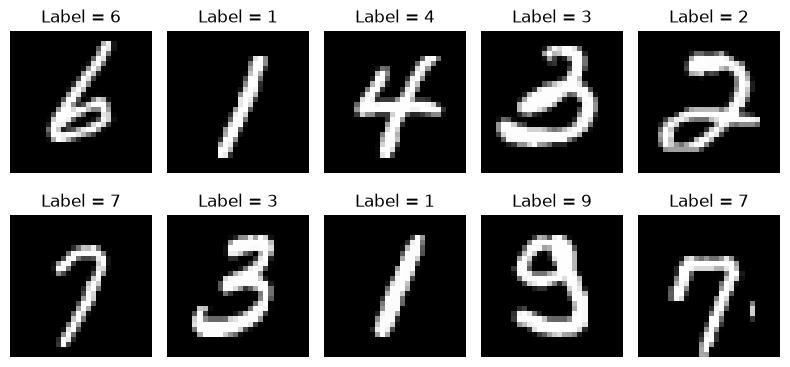

In [7]:

import matplotlib.pyplot as plt

images, labels = next(iter(train_loader))

fig, axes = plt.subplots(2, 5, figsize=(8, 4))

for i, ax in enumerate(axes.flat):
    ax.imshow(images[i].squeeze(), cmap="gray")
    ax.set_title(f"Label = {labels[i].item()}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [8]:

class Classifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.net(x)

classifier = Classifier().to(device)
classifier


Classifier(
  (net): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=10, bias=True)
  )
)

In [9]:

criterion = nn.CrossEntropyLoss()

optimizer = torch.optim.Adam(
    classifier.parameters(),
    lr=1e-3
)


In [10]:

def train_classifier(model, loader, epochs=3):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            loss = criterion(logits, y)

            optimizer.zero_grad()
            loss.backward()
            optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )

train_classifier(classifier, train_loader, epochs=3)


Epoch 1/3 - Loss = 0.4161
Epoch 2/3 - Loss = 0.1971
Epoch 3/3 - Loss = 0.1428


In [11]:

def evaluate_classifier(model, loader):
    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)

            logits = model(x)
            pred = logits.argmax(dim=1)

            correct += (pred == y).sum().item()
            total += y.size(0)

    return correct / total


accuracy = evaluate_classifier(classifier, test_loader)

print(f"Accuracy = {100 * accuracy:.2f}%")


Accuracy = 96.19%


In [12]:
    
class Autoencoder(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 128),
            nn.ReLU(),
            nn.Linear(128, 32),
            nn.ReLU(),
            nn.Linear(32, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 128),
            nn.ReLU(),
            nn.Linear(128, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat


ae = Autoencoder(latent_dim=2).to(device)
ae


Autoencoder(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=32, bias=True)
    (4): ReLU()
    (5): Linear(in_features=32, out_features=2, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [15]:
ae_criterion = nn.MSELoss()

ae_optimizer = torch.optim.Adam(
    ae.parameters(),
    lr=1e-3
)

In [16]:

def train_autoencoder(model, loader, epochs=5):
    model.train()

    for epoch in range(epochs):
        total_loss = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat = model(x)
            loss = ae_criterion(x_hat, x)

            ae_optimizer.zero_grad()
            loss.backward()
            ae_optimizer.step()

            total_loss += loss.item()

        print(
            f"Epoch {epoch+1}/{epochs} - "
            f"Loss = {total_loss/len(loader):.4f}"
        )


train_autoencoder(ae, train_loader, epochs=5)

Epoch 1/5 - Loss = 0.0649
Epoch 2/5 - Loss = 0.0522
Epoch 3/5 - Loss = 0.0487
Epoch 4/5 - Loss = 0.0463
Epoch 5/5 - Loss = 0.0448


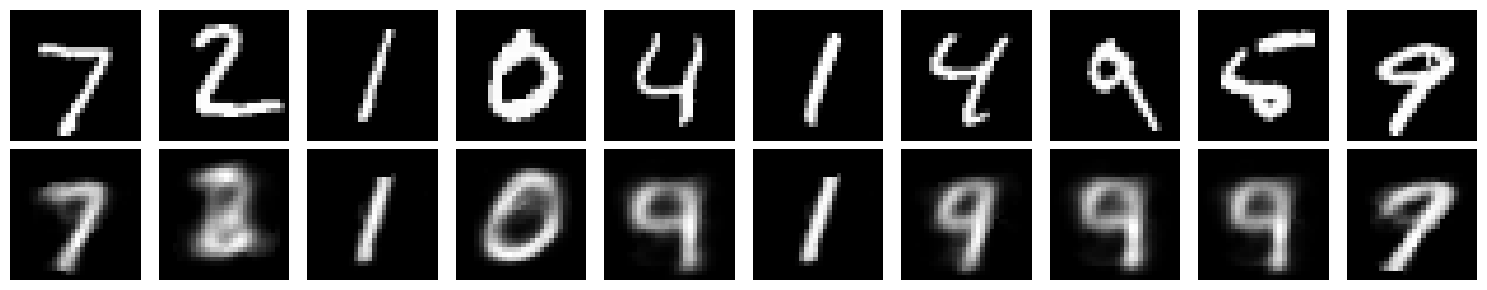

In [17]:

ae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat = ae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstruit")

plt.tight_layout()
plt.show()

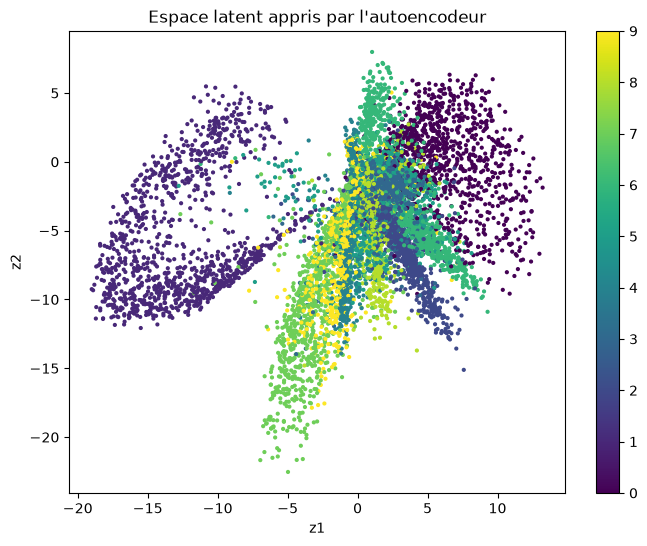

In [18]:

ae.eval()

zs = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)
        z = ae.encode(x)

        zs.append(z.cpu())
        ys.append(y)

Z = torch.cat(zs).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    Z[:, 0],
    Z[:, 1],
    c=Y,
    s=4
)

plt.xlabel("z1")
plt.ylabel("z2")
plt.title("Espace latent appris par l'autoencodeur")
plt.colorbar(scatter)
plt.show()

In [19]:

class VAE(nn.Module):
    def __init__(self, latent_dim=2):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Flatten(),
            nn.Linear(784, 256),
            nn.ReLU(),
            nn.Linear(256, 64),
            nn.ReLU()
        )

        self.fc_mu = nn.Linear(64, latent_dim)
        self.fc_logvar = nn.Linear(64, latent_dim)

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 64),
            nn.ReLU(),
            nn.Linear(64, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder(x)
        mu = self.fc_mu(h)
        logvar = self.fc_logvar(h)
        return mu, logvar

    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        x_hat = self.decoder(z)
        return x_hat.view(-1, 1, 28, 28)

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        x_hat = self.decode(z)
        return x_hat, mu, logvar


vae = VAE(latent_dim=2).to(device)
vae

VAE(
  (encoder): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=784, out_features=256, bias=True)
    (2): ReLU()
    (3): Linear(in_features=256, out_features=64, bias=True)
    (4): ReLU()
  )
  (fc_mu): Linear(in_features=64, out_features=2, bias=True)
  (fc_logvar): Linear(in_features=64, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=64, bias=True)
    (1): ReLU()
    (2): Linear(in_features=64, out_features=256, bias=True)
    (3): ReLU()
    (4): Linear(in_features=256, out_features=784, bias=True)
    (5): Sigmoid()
  )
)

In [20]:

x, _ = next(iter(train_loader))
x = x[:5].to(device)

x_hat, mu, logvar = vae(x)

print("Input shape:", x.shape)
print("Reconstruction shape:", x_hat.shape)
print("Mu shape:", mu.shape)
print("Logvar shape:", logvar.shape)

Input shape: torch.Size([5, 1, 28, 28])
Reconstruction shape: torch.Size([5, 1, 28, 28])
Mu shape: torch.Size([5, 2])
Logvar shape: torch.Size([5, 2])


In [21]:

def vae_loss(x_hat, x, mu, logvar, beta=1.0):
    rec_loss = F.binary_cross_entropy(
        x_hat,
        x,
        reduction="sum"
    )

    kl_loss = -0.5 * torch.sum(
        1 + logvar - mu.pow(2) - logvar.exp()
    )

    return rec_loss + beta * kl_loss, rec_loss, kl_loss

In [22]:

vae_optimizer = torch.optim.Adam(
    vae.parameters(),
    lr=1e-3
)


In [23]:

def train_vae(model, loader, epochs=20, beta=1.0):
    model.train()

    for epoch in range(epochs):
        total_loss = 0
        total_rec = 0
        total_kl = 0

        for x, _ in loader:
            x = x.to(device)

            x_hat, mu, logvar = model(x)

            loss, rec, kl = vae_loss(
                x_hat, x, mu, logvar, beta=beta
            )

            vae_optimizer.zero_grad()
            loss.backward()
            vae_optimizer.step()

            total_loss += loss.item()
            total_rec += rec.item()
            total_kl += kl.item()

        n = len(loader.dataset)

        print(
            f"Epoch {epoch+1}/{epochs} | "
            f"Loss={total_loss/n:.2f} | "
            f"Rec={total_rec/n:.2f} | "
            f"KL={total_kl/n:.2f}"
        )


train_vae(vae, train_loader, epochs=20)

Epoch 1/20 | Loss=193.95 | Rec=190.32 | KL=3.63
Epoch 2/20 | Loss=165.60 | Rec=160.65 | KL=4.95
Epoch 3/20 | Loss=160.03 | Rec=154.74 | KL=5.29
Epoch 4/20 | Loss=156.09 | Rec=150.54 | KL=5.55
Epoch 5/20 | Loss=153.40 | Rec=147.68 | KL=5.72
Epoch 6/20 | Loss=151.42 | Rec=145.55 | KL=5.87
Epoch 7/20 | Loss=149.90 | Rec=143.94 | KL=5.96
Epoch 8/20 | Loss=148.71 | Rec=142.67 | KL=6.05
Epoch 9/20 | Loss=147.75 | Rec=141.63 | KL=6.12
Epoch 10/20 | Loss=146.80 | Rec=140.62 | KL=6.18
Epoch 11/20 | Loss=146.17 | Rec=139.96 | KL=6.21
Epoch 12/20 | Loss=145.66 | Rec=139.41 | KL=6.25
Epoch 13/20 | Loss=145.05 | Rec=138.77 | KL=6.28
Epoch 14/20 | Loss=144.40 | Rec=138.09 | KL=6.31
Epoch 15/20 | Loss=144.09 | Rec=137.73 | KL=6.36
Epoch 16/20 | Loss=143.88 | Rec=137.52 | KL=6.36
Epoch 17/20 | Loss=143.47 | Rec=137.07 | KL=6.39
Epoch 18/20 | Loss=143.10 | Rec=136.68 | KL=6.42
Epoch 19/20 | Loss=142.75 | Rec=136.30 | KL=6.45
Epoch 20/20 | Loss=142.42 | Rec=135.97 | KL=6.45


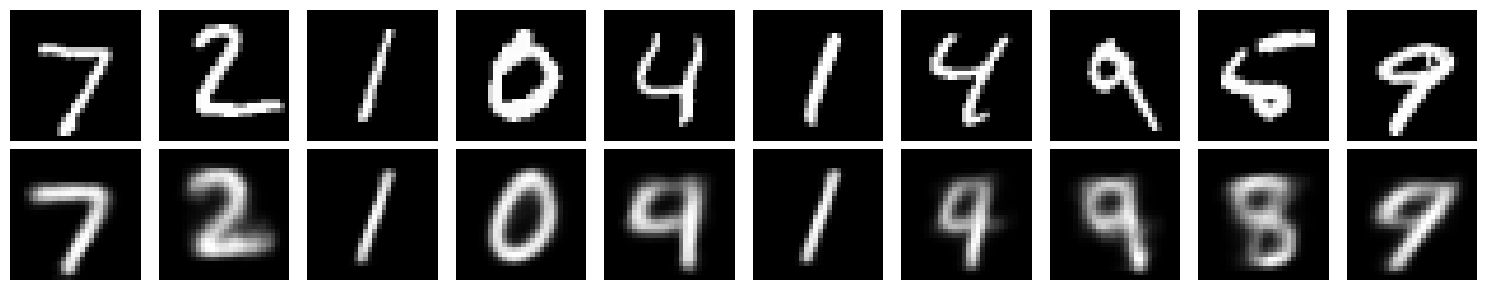

In [24]:
    
vae.eval()

x, _ = next(iter(test_loader))
x = x[:10].to(device)

with torch.no_grad():
    x_hat, _, _ = vae(x)

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[0, i].axis("off")

    axes[1, i].imshow(x_hat[i].cpu().squeeze(), cmap="gray")
    axes[1, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("VAE")

plt.tight_layout()
plt.show()

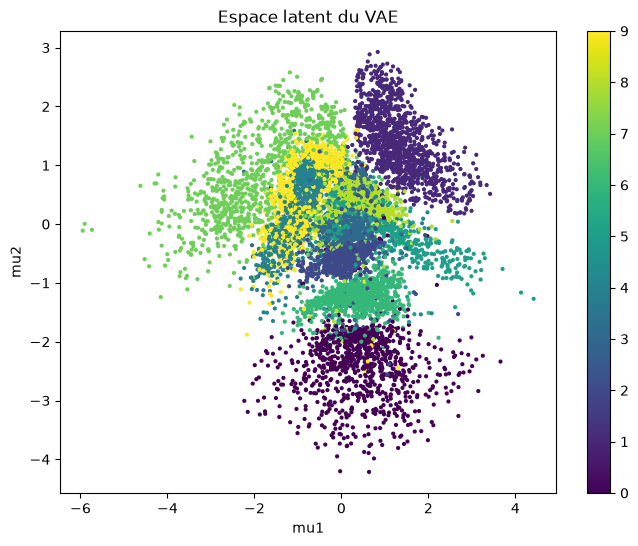

In [25]:

vae.eval()

mus = []
ys = []

with torch.no_grad():
    for x, y in test_loader:
        x = x.to(device)

        mu, logvar = vae.encode(x)

        mus.append(mu.cpu())
        ys.append(y)

MU = torch.cat(mus).numpy()
Y = torch.cat(ys).numpy()

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    MU[:, 0],
    MU[:, 1],
    c=Y,
    s=4
)

plt.xlabel("mu1")
plt.ylabel("mu2")
plt.title("Espace latent du VAE")
plt.colorbar(scatter)
plt.show()

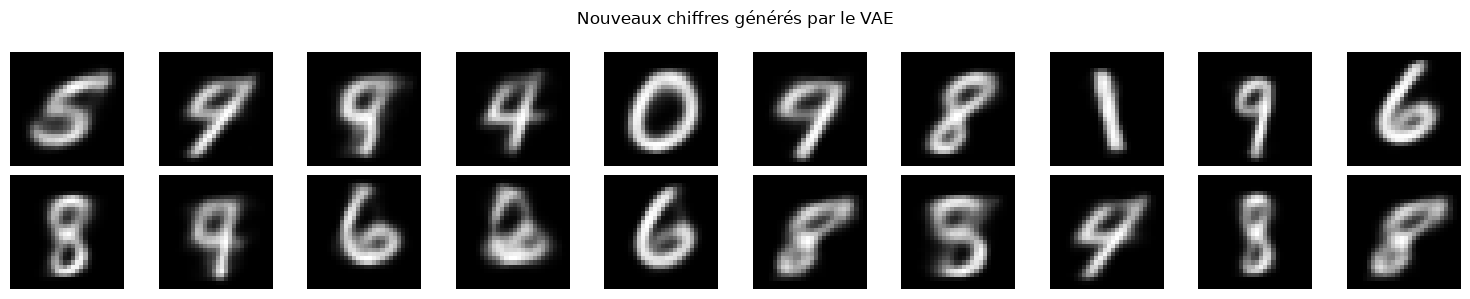

In [26]:

vae.eval()

with torch.no_grad():
    z = torch.randn(20, 2).to(device)
    samples = vae.decode(z).cpu()

fig, axes = plt.subplots(2, 10, figsize=(15, 3))

for i, ax in enumerate(axes.flat):
    ax.imshow(samples[i].squeeze(), cmap="gray")
    ax.axis("off")

plt.suptitle("Nouveaux chiffres générés par le VAE")
plt.tight_layout()
plt.show()


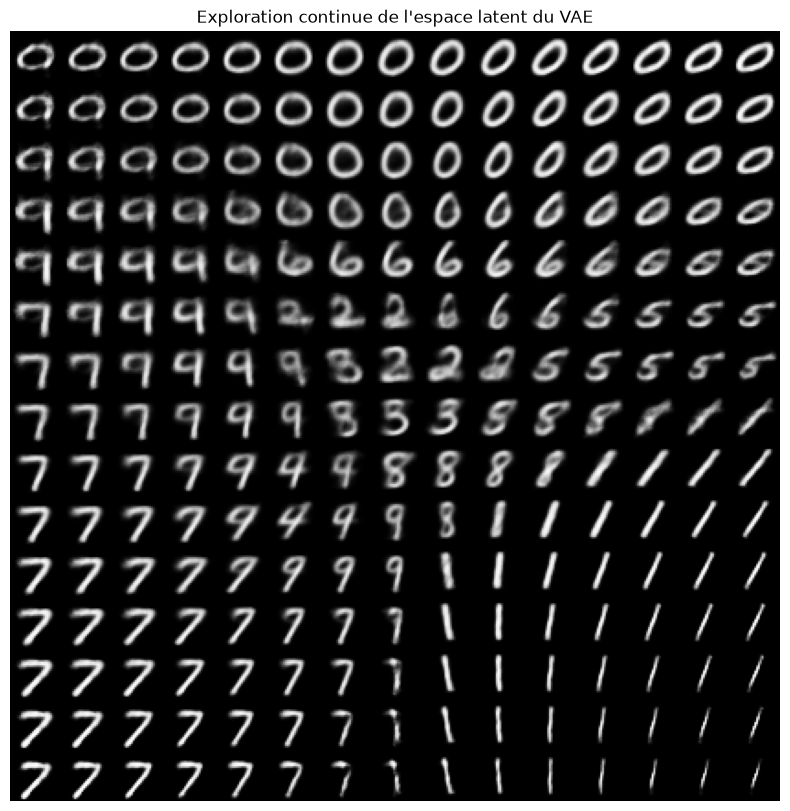

In [27]:
vae.eval()

grid_x = np.linspace(-3, 3, 15)
grid_y = np.linspace(-3, 3, 15)

figure = np.zeros((28 * 15, 28 * 15))

with torch.no_grad():
    for i, yi in enumerate(grid_y):
        for j, xi in enumerate(grid_x):
            z = torch.tensor(
                [[xi, yi]],
                dtype=torch.float32,
                device=device
            )
            x_hat = vae.decode(z)
            digit = x_hat.cpu().numpy()[0, 0]

            figure[
                i*28:(i+1)*28,
                j*28:(j+1)*28
            ] = digit

plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap="gray")
plt.axis("off")
plt.title("Exploration continue de l'espace latent du VAE")
plt.show()

In [1]:
from pathlib import Path
import torch
from torch import nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from torchvision.utils import save_image

torch.manual_seed(42)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

latent_dim = 100
image_dim = 28 * 28
batch_size = 128
epochs = 20
learning_rate = 0.0002

output_dir = Path("images_generees")
output_dir.mkdir(exist_ok=True)

print(f"Appareil utilisé : {device}")

Appareil utilisé : cpu


In [2]:
gan_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

gan_dataset = datasets.MNIST(
    root="data",
    train=True,
    download=True,
    transform=gan_transform,
)

loader = DataLoader(gan_dataset, batch_size=batch_size, shuffle=True)

In [3]:
class Generator(nn.Module):
    def __init__(self, latent_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(latent_dim, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, image_dim),
            nn.Tanh(),
        )

    def forward(self, noise):
        return self.network(noise)

class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(image_dim, 512),
            nn.LeakyReLU(0.2),
            nn.Linear(512, 256),
            nn.LeakyReLU(0.2),
            nn.Linear(256, 1),
        )

    def forward(self, images):
        return self.network(images)

generator = Generator(latent_dim).to(device)
discriminator = Discriminator().to(device)

# Named differently so the classifier's `criterion` from earlier isn't overwritten
gan_criterion = nn.BCEWithLogitsLoss()

optimizer_g = torch.optim.Adam(generator.parameters(), lr=learning_rate, betas=(0.5, 0.999))
optimizer_d = torch.optim.Adam(discriminator.parameters(), lr=learning_rate, betas=(0.5, 0.999))

In [4]:
fixed_noise = torch.randn(64, latent_dim, device=device)

for epoch in range(epochs):
    generator.train()
    discriminator.train()
    total_loss_d, total_loss_g = 0.0, 0.0

    for real_images, _ in loader:
        # [B, 1, 28, 28] -> [B, 784]
        real_images = real_images.to(device).flatten(start_dim=1)
        current_batch_size = real_images.size(0)

        real_labels = torch.ones(current_batch_size, 1, device=device)
        fake_labels = torch.zeros(current_batch_size, 1, device=device)

        # A. Train the discriminator
        discriminator.requires_grad_(True)
        optimizer_d.zero_grad(set_to_none=True)

        real_scores = discriminator(real_images)
        loss_real = gan_criterion(real_scores, real_labels)

        noise = torch.randn(current_batch_size, latent_dim, device=device)
        fake_images = generator(noise)

        # detach: no gradient flows to G during this step
        fake_scores = discriminator(fake_images.detach())
        loss_fake = gan_criterion(fake_scores, fake_labels)

        loss_d = (loss_real + loss_fake) / 2
        loss_d.backward()
        optimizer_d.step()

        # B. Train the generator
        discriminator.requires_grad_(False)
        optimizer_g.zero_grad(set_to_none=True)

        fake_scores = discriminator(fake_images)
        # G wants its images to be classified as "real"
        loss_g = gan_criterion(fake_scores, real_labels)
        loss_g.backward()
        optimizer_g.step()

        total_loss_d += loss_d.item()
        total_loss_g += loss_g.item()

    print(
        f"Époque {epoch + 1:02d}/{epochs} | "
        f"Loss D : {total_loss_d / len(loader):.4f} | "
        f"Loss G : {total_loss_g / len(loader):.4f}"
    )

    # C. Save examples
    generator.eval()
    with torch.no_grad():
        samples = generator(fixed_noise).view(-1, 1, 28, 28)
        samples = (samples + 1) / 2   # [-1, 1] -> [0, 1]
        save_image(samples, output_dir / f"epoch_{epoch + 1:03d}.png", nrow=8)

torch.save(generator.state_dict(), "generator_mnist.pt")

Époque 01/20 | Loss D : 0.4405 | Loss G : 1.4161
Époque 02/20 | Loss D : 0.3543 | Loss G : 2.1691
Époque 03/20 | Loss D : 0.3247 | Loss G : 2.4462
Époque 04/20 | Loss D : 0.3207 | Loss G : 2.4961
Époque 05/20 | Loss D : 0.3099 | Loss G : 2.5721
Époque 06/20 | Loss D : 0.3464 | Loss G : 2.2689
Époque 07/20 | Loss D : 0.2938 | Loss G : 2.5984
Époque 08/20 | Loss D : 0.3044 | Loss G : 2.6211
Époque 09/20 | Loss D : 0.3055 | Loss G : 2.6300
Époque 10/20 | Loss D : 0.3049 | Loss G : 2.6626
Époque 11/20 | Loss D : 0.2857 | Loss G : 2.6051
Époque 12/20 | Loss D : 0.2914 | Loss G : 2.7132
Époque 13/20 | Loss D : 0.2974 | Loss G : 2.4950
Époque 14/20 | Loss D : 0.3303 | Loss G : 2.2616
Époque 15/20 | Loss D : 0.3625 | Loss G : 2.1018
Époque 16/20 | Loss D : 0.3704 | Loss G : 1.9852
Époque 17/20 | Loss D : 0.4079 | Loss G : 1.7792
Époque 18/20 | Loss D : 0.4183 | Loss G : 1.6946
Époque 19/20 | Loss D : 0.4451 | Loss G : 1.6037
Époque 20/20 | Loss D : 0.4574 | Loss G : 1.5300


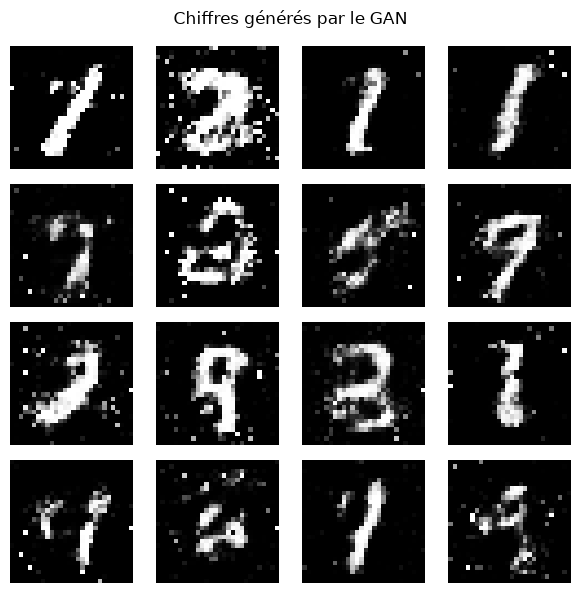

In [5]:
import matplotlib.pyplot as plt

generator.eval()
with torch.no_grad():
    noise = torch.randn(16, latent_dim, device=device)
    images = generator(noise)
    images = images.reshape(-1, 1, 28, 28)
    images = ((images + 1) / 2).clamp(0, 1)   # [-1, 1] -> [0, 1]
    images = images.cpu()

save_image(images, output_dir / "nouveaux_chiffres.png", nrow=4)

fig, axes = plt.subplots(4, 4, figsize=(6, 6))
for ax, image in zip(axes.flat, images):
    ax.imshow(image.squeeze(0).numpy(), cmap="gray", vmin=0, vmax=1)
    ax.axis("off")

fig.suptitle("Chiffres générés par le GAN")
plt.tight_layout()
plt.show()

In [6]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Périphérique :", device)

diff_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),
])

train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=diff_transform,
)

train_loader = DataLoader(
    train_dataset,
    batch_size=128,
    shuffle=True,
    num_workers=0,
    pin_memory=(device.type == "cuda"),
)

Périphérique : cpu


In [7]:
T = 200

def cosine_beta_schedule(timesteps, s=0.008):
    steps = torch.linspace(0, timesteps, timesteps + 1)
    alpha_bar = torch.cos(((steps / timesteps + s) / (1 + s)) * math.pi / 2).pow(2)
    alpha_bar = alpha_bar / alpha_bar[0]
    betas = 1 - alpha_bar[1:] / alpha_bar[:-1]
    return betas.clamp(min=1e-4, max=0.999)

betas = cosine_beta_schedule(T).to(device)
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
alpha_bars_prev = torch.cat([torch.ones(1, device=device), alpha_bars[:-1]])

posterior_variance = betas * (1 - alpha_bars_prev) / (1 - alpha_bars)

def extract(values, t):
    """Sélectionner un coefficient par image"""
    return values[t].view(-1, 1, 1, 1)

def add_noise(x0, t, noise=None):
    if noise is None:
        noise = torch.randn_like(x0)
    signal = extract(alpha_bars.sqrt(), t)
    noise_scale = extract((1 - alpha_bars).sqrt(), t)
    xt = signal * x0 + noise_scale * noise
    return xt, noise

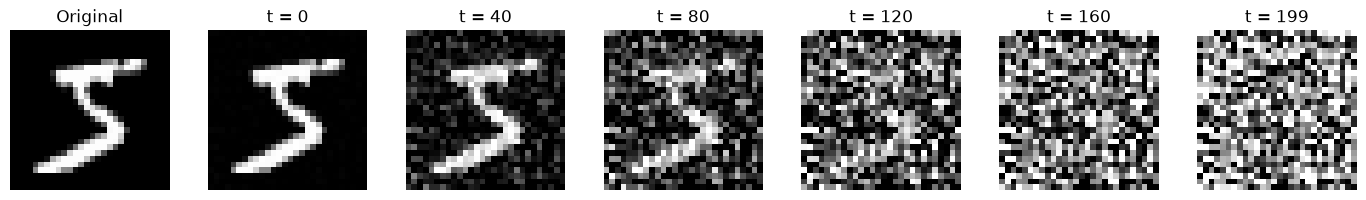

In [8]:
x0, _ = train_dataset[0]
x0 = x0.unsqueeze(0).to(device)

times = [0, 40, 80, 120, 160, 199]
noise = torch.randn_like(x0)

fig, axes = plt.subplots(1, len(times) + 1, figsize=(14, 2))

axes[0].imshow(x0[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
axes[0].set_title("Original")
axes[0].axis("off")

for ax, step in zip(axes[1:], times):
    t = torch.tensor([step], device=device)
    xt, _ = add_noise(x0, t, noise)
    ax.imshow(xt[0, 0].cpu(), cmap="gray", vmin=-1, vmax=1)
    ax.set_title(f"t = {step}")
    ax.axis("off")

plt.tight_layout()
plt.show()